# **Data Quality Assessment & Data Cleansing**
Online Retail

**Baca Dataset**

In [ ]:
import pandas as pd
df = pd.read_csv("online_retail_dirty.csv")
df.head()

,order_id,order_date,customer_id,customer_name,email,phone,city,province,product_category,product_name,quantity,unit_price_idr,discount_pct,payment_method,order_status,shipping_days,total_amount_idr
0,ORD-2026-0117,10-01-2026,CUST-0026,Maya Nugroho,maya.nugroho026@example.com,0837-1000-962,Tangerang,Banten,Kecantikan,Sunscreen SPF 50,3,Rp66.000,25,Bank Transfer,shipped,3,Rp 762.258
1,ORD-2025-0278,17/12/2025,CUST-0023,Galih Prakoso,galih.prakoso023@example.com,0834-1000-851,Bekasi,Jawa Barat,FASHION,Cotton Hoodie,1,Rp263.000,20%,Cash On Delivery,Delivered,4,Rp210.400
2,ORD-2026-0048,13/06/2026,CUST-0006,Rizky Pertiwi,rizky.pertiwi006@example.com,+628171000222,Bogor,Jawa Barat,BEAUTY,Lip Balm,3,Rp134.000,0 %,E-Wallet,Delivered,8,"402,000"
3,ORD-2025-0054,18-11-2025,CUST-0017,Nabila Ramadhan,NaN,+62 828 1000 629,Jakarta Selatan,DKI Jakarta,Home and Living,Storage Organizer,2.5,"41,000",0.15,e-wallet,PROCESSING,0,Rp174.250
4,ORD-2025-0108,26/11/2025,CUST-0051,anisa setiawan,user@,08621001887,Makassar,Sulawesi Selatan,FASHION,Basic T-Shirt,3,Rp46.000,10 %,bank transfer,Selesai,8,124200


Jumlah Baris dan Kolom

In [ ]:
print("Jumlah baris dan kolom:", df.shape)
print("Jumlah record:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

Jumlah baris dan kolom: (350, 17)
Jumlah record: 350
Jumlah kolom: 17


# **Data Profiling**

## **1. MISSING VALUE ANALYSIS**

In [ ]:
missing_summary = pd.DataFrame({
    "Jumlah Missing": df.isna().sum(),
    "Persentase Missing (%)": (
        df.isna().mean() * 100
    ).round(2)
})

# Urutkan dari jumlah missing terbanyak
missing_summary = missing_summary.sort_values(
    by="Jumlah Missing",
    ascending=False
)

# Tampilkan hanya kolom yang memiliki missing value
missing_summary = missing_summary[
    missing_summary["Jumlah Missing"] > 0
]

display(missing_summary)

print("Total missing value:", df.isna().sum().sum())
print("Jumlah kolom yang memiliki missing value:",
      len(missing_summary))

,Jumlah Missing,Persentase Missing (%)
shipping_days,17,4.86
city,16,4.57
phone,15,4.29
email,12,3.43
discount_pct,7,2.00
province,5,1.43
payment_method,5,1.43
product_name,3,0.86
customer_name,3,0.86
quantity,2,0.57


Total missing value: 87
Jumlah kolom yang memiliki missing value: 11


## **2. DUPLICATE DATA ANALYSIS**

In [ ]:
# Menghitung duplikasi berdasarkan seluruh kolom
duplicate_count = df.duplicated().sum()

print("Total record:", len(df))
print("Jumlah baris duplikat:", duplicate_count)
print("Jumlah record unik:",
      len(df) - duplicate_count)

Total record: 350
Jumlah baris duplikat: 15
Jumlah record unik: 335


In [ ]:
# Menampilkan seluruh baris yang termasuk kelompok duplikat

duplicate_rows = df[df.duplicated(keep=False)]

print("Jumlah baris dalam kelompok duplikat:",
      len(duplicate_rows))

display(duplicate_rows)

Jumlah baris dalam kelompok duplikat: 30


,order_id,order_date,customer_id,customer_name,email,phone,city,province,product_category,product_name,quantity,unit_price_idr,discount_pct,payment_method,order_status,shipping_days,total_amount_idr
0,ORD-2026-0117,10-01-2026,CUST-0026,Maya Nugroho,maya.nugroho026@example.com,0837-1000-962,Tangerang,Banten,Kecantikan,Sunscreen SPF 50,3,Rp66.000,25,Bank Transfer,shipped,3,Rp 762.258
14,ORD-2026-0041,2026-03-20,CUST-0090,Nadia Amalia,nadia.amalia090@example.com,+62 813 1003 330,Yogyakarta,DI Yogyakarta,Home & Living,Ceramic Mug,2,98000,15 %,Cash On Delivery,Selesai,1,Rp166.600
49,ORD-2026-0185,10-09-2026,CUST-0066,lestari hidayat,lestari.hidayat066@example.com,+62 877 1002 442,NaN,Jawa Timur,GROCERIES,Honey 250ml,1,Rp59.000,15 %,Transfer Bank,delivered,9,"50,150"
50,ORD-2026-0180,2026-07-26,CUST-0015,Aulia Hakim,aulia.hakim015@example.com,+62 826 1000 555,Malang,Jawa Timur,sports,Gym Bottle,1,110000,10%,Transfer Bank,DELIVERED,5,"99,000"
58,ORD-2026-0245,2026/08/06,CUST-0080,Ayu Maulana,ayu.maulana080@example.com,08911002960,Medan,Sumatera Utara,SPORTS,SKIPPING ROPE,4,"75,000",150,Transfer Bank,Selesai,6,285000
62,ORD-2026-0243,28-09-2026,CUST-0047,Budi Wulandari,budi.wulandari047@example.com,0858-1001-739,Ponorogo,Jawa Timur,electronics,Mechanical Keyboard,4,Rp500.000,25 %,Bank Transfer,Selesai,8,Rp 1.500.000
63,ORD-2026-0023,05/03/2026,CUST-0040,dinda mahendra,dinda.mahendra040@example.com,0851-1001-480,Makassar,Sulawesi Selatan,books,Sketching Journal,4,"114,000",5%,Cash on Delivery,Delivered,5,Rp 433.200
68,ORD-2026-0037,20-04-2026,CUST-0032,Dani Hidayat,dani.hidayat032@example.com,0843-1001-184,Tangerang,Banten,Fashion,Basic T-Shirt,5,"151,000",15,e-wallet,cancelled,2,Rp334.729
82,ORD-2026-0030,2026/08/20,CUST-0050,Rizky Wibowo,RIZKY.WIBOWO050@EXAMPLE.COM,+628611001850,Denpasar,bali,electronics,USB-C Charger,4,Rp797.000,25 %,Cash on Delivery,Selesai,3,2391000
88,ORD-2026-0030,2026/08/20,CUST-0050,Rizky Wibowo,RIZKY.WIBOWO050@EXAMPLE.COM,+628611001850,Denpasar,bali,electronics,USB-C Charger,4,Rp797.000,25 %,Cash on Delivery,Selesai,3,2391000


In [ ]:
# Menghitung jumlah kemunculan setiap baris identik

duplicate_groups = (
    df.groupby(list(df.columns), dropna=False)
      .size()
      .reset_index(name="jumlah_kemunculan")
)

duplicate_groups = duplicate_groups[
    duplicate_groups["jumlah_kemunculan"] > 1
]

display(duplicate_groups)

print("Jumlah kelompok duplikat:", len(duplicate_groups))
print(
    "Total kemunculan tambahan:",
    (duplicate_groups["jumlah_kemunculan"] - 1).sum()
)

,order_id,order_date,customer_id,customer_name,email,phone,city,province,product_category,product_name,quantity,unit_price_idr,discount_pct,payment_method,order_status,shipping_days,total_amount_idr,jumlah_kemunculan
44,ORD-2025-0217,07/11/2025,CUST-0087,FARHAN SAPUTRA,farhan.saputra087@example.com,08981003219,Madiun,Jawa Timur,beauty,Shampoo Herbal,5,"41,000",0,OVO,Selesai,2,"205,000",2
80,ORD-2026-0023,05/03/2026,CUST-0040,dinda mahendra,dinda.mahendra040@example.com,0851-1001-480,Makassar,Sulawesi Selatan,books,Sketching Journal,4,"114,000",5%,Cash on Delivery,Delivered,5,Rp 433.200,2
87,ORD-2026-0030,2026/08/20,CUST-0050,Rizky Wibowo,RIZKY.WIBOWO050@EXAMPLE.COM,+628611001850,Denpasar,bali,electronics,USB-C Charger,4,Rp797.000,25 %,Cash on Delivery,Selesai,3,2391000,2
89,ORD-2026-0032,29-01-2026,CUST-0011,Bayu Setiawan,bayu.setiawan011@example.com,08221000407,Jakarta Timur,DKI Jakarta,Buku,Business Workbook,4,Rp66.000,0,COD,shipped,NaN,Rp264.000,2
93,ORD-2026-0037,20-04-2026,CUST-0032,Dani Hidayat,dani.hidayat032@example.com,0843-1001-184,Tangerang,Banten,Fashion,Basic T-Shirt,5,"151,000",15,e-wallet,cancelled,2,Rp334.729,2
96,ORD-2026-0041,2026-03-20,CUST-0090,Nadia Amalia,nadia.amalia090@example.com,+62 813 1003 330,Yogyakarta,DI Yogyakarta,Home & Living,Ceramic Mug,2,98000,15 %,Cash On Delivery,Selesai,1,Rp166.600,2
106,ORD-2026-0059,2026/09/12,CUST-0054,Citra Nugroho,CITRA.NUGROHO054@EXAMPLE.COM,+628651001998,NaN,Jawa Barat,groceries,HONEY 250ML,5,Rp104.000,5 %,E-Wallet,Processing,0,Rp494.000,2
134,ORD-2026-0093,31/14/2026,CUST-0083,Yoga Fauzi,yoga.fauzi083@example.com,0894-1003-071,Balikpapan,Kalimantan Timur,Books,Sketching Journal,1,Rp107.000,0 %,e-wallet,Diproses,0,107000,2
153,ORD-2026-0117,10-01-2026,CUST-0026,Maya Nugroho,maya.nugroho026@example.com,0837-1000-962,Tangerang,Banten,Kecantikan,Sunscreen SPF 50,3,Rp66.000,25,Bank Transfer,shipped,3,Rp 762.258,2
159,ORD-2026-0127,08-09-2026,CUST-0089,Budi Pratama,budi.pratama089@example.com,0812-1003-293,Jakarta Timur,DKI Jakarta,HOME & LIVING,Bedsheet Set,4,-50000,0 %,COD,SHIPPED,9,Rp372.000,2


Jumlah kelompok duplikat: 15
Total kemunculan tambahan: 15


Kesimpulan:
Berdasarkan hasil Duplicate Data Analysis, dataset online retail memiliki 350 record dengan 15 record duplikat tambahan. Jumlah tersebut setara dengan 4,29% dari keseluruhan record. Duplikasi diidentifikasi berdasarkan kesamaan seluruh atribut pada setiap baris. Temuan ini menunjukkan adanya pengulangan data yang perlu ditinjau dan ditangani pada tahap Data Cleansing untuk mengurangi risiko penghitungan transaksi secara berulang.

## **3. UNIQUE VALUE ANALYSIS**

In [ ]:
unique_summary = pd.DataFrame({
    "Jumlah Nilai Unik": df.nunique(),
    "Jumlah Missing": df.isna().sum()
})

unique_summary = unique_summary.sort_values(
    by="Jumlah Nilai Unik",
    ascending=True
)

display(unique_summary)

,Jumlah Nilai Unik,Jumlah Missing
shipping_days,12,17
quantity,14,2
payment_method,16,5
order_status,20,0
province,21,5
discount_pct,27,7
product_category,28,0
city,43,16
product_name,64,3
customer_id,92,0


In [ ]:
# Memeriksa nilai unik pada kolom kategori

category_columns = [
    "product_category",
    "payment_method",
    "order_status",
    "province"
]

for col in category_columns:
    print(f"\n===== {col.upper()} =====")

    value_counts = (
        df[col]
        .value_counts(dropna=False)
        .rename_axis("Nilai")
        .reset_index(name="Jumlah")
    )

    display(value_counts)


===== PRODUCT_CATEGORY =====


,Nilai,Jumlah
0,Fashion,19
1,books,17
2,HOME & LIVING,16
3,electronics,16
4,fashion,16
5,Olahraga,16
6,SPORTS,16
7,groceries,15
8,Elektronik,14
9,Books,13



===== PAYMENT_METHOD =====


,Nilai,Jumlah
0,Bank Transfer,30
1,Cash On Delivery,28
2,Transfer Bank,27
3,Cash on Delivery,26
4,Kartu Kredit,24
5,Transfer Bank,22
6,cod,21
7,bank transfer,21
8,e-wallet,21
9,Ewallet,20



===== ORDER_STATUS =====


,Nilai,Jumlah
0,delivered,43
1,Delivered,42
2,Selesai,38
3,DELIVERED,31
4,Shipped,22
5,SHIPPED,22
6,Processing,18
7,Diproses,16
8,shipped,15
9,cancelled,14



===== PROVINCE =====


,Nilai,Jumlah
0,Jawa Timur,81
1,Jawa Barat,49
2,Jawa Tengah,34
3,Banten,32
4,DKI Jakarta,30
5,Kalimantan Timur,21
6,DI Yogyakarta,19
7,Sulawesi Selatan,18
8,Bali,15
9,Sumatera Utara,13


In [ ]:
# Membandingkan nilai unik sebelum dan sesudah normalisasi sederhana

for col in category_columns:
    unique_before = df[col].nunique()

    normalized_values = (
        df[col]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    unique_after = normalized_values.nunique()

    print(f"\nKolom: {col}")
    print("Nilai unik sebelum normalisasi:", unique_before)
    print("Nilai unik setelah normalisasi:", unique_after)
    print("Selisih nilai unik:", unique_before - unique_after)


Kolom: product_category
Nilai unik sebelum normalisasi: 28
Nilai unik setelah normalisasi: 14
Selisih nilai unik: 14

Kolom: payment_method
Nilai unik sebelum normalisasi: 16
Nilai unik setelah normalisasi: 10
Selisih nilai unik: 6

Kolom: order_status
Nilai unik sebelum normalisasi: 20
Nilai unik setelah normalisasi: 10
Selisih nilai unik: 10

Kolom: province
Nilai unik sebelum normalisasi: 21
Nilai unik setelah normalisasi: 11
Selisih nilai unik: 10


Kesimpulan:
Hasil Unique Value Analysis menunjukkan adanya variasi nilai pada beberapa atribut kategorikal, khususnya kategori produk, metode pembayaran, status pesanan, dan provinsi. Variasi tersebut mencakup perbedaan kapitalisasi, penggunaan spasi, serta penggunaan istilah dalam bahasa Indonesia dan bahasa Inggris. Kondisi ini berpotensi menghasilkan kategori yang terhitung berbeda meskipun memiliki makna yang sama. Oleh karena itu, setiap variasi perlu diverifikasi sebelum dilakukan standardisasi pada tahap Data Cleansing.

## **4. FORMAT INCONSISTENCY ANALYSIS**

In [ ]:
# Pemeriksaan format tanggal

import re from datetime import datetime

def check_date_format(value):
    if pd.isna(value) or str(value).strip() == "":
        return "Missing"

    value = str(value).strip()

    formats = [
        ("YYYY-MM-DD", r"\d{4}-\d{2}-\d{2}", "%Y-%m-%d"),
        ("YYYY/MM/DD", r"\d{4}/\d{2}/\d{2}", "%Y/%m/%d"),
        ("DD/MM/YYYY", r"\d{1,2}/\d{1,2}/\d{4}", "%d/%m/%Y"),
        ("DD-MM-YYYY", r"\d{1,2}-\d{1,2}-\d{4}", "%d-%m-%Y"),
        ("DD Mon YYYY", r"\d{1,2} [A-Za-z]{3,9} \d{4}", "MONTH")
    ]

    for label, pattern, date_format in formats:
        if re.fullmatch(pattern, value):
            try:
                if date_format == "MONTH":
                    try:
                        datetime.strptime(value, "%d %b %Y")
                    except ValueError:
                        datetime.strptime(value, "%d %B %Y")
                else:
                    datetime.strptime(value, date_format)
                return label
            except ValueError:
                return "Tanggal tidak valid"
    return "Format tidak dikenali"
date_format = df["order_date"].apply(check_date_format)
date_summary = (
    date_format.value_counts()
    .rename_axis("Format Tanggal")
    .reset_index(name="Jumlah Record")
)

display(date_summary)

,Format Tanggal,Jumlah Record
0,YYYY/MM/DD,81
1,DD-MM-YYYY,74
2,DD/MM/YYYY,69
3,YYYY-MM-DD,64
4,DD Mon YYYY,57
5,Tanggal tidak valid,4
6,Format tidak dikenali,1


In [ ]:
date_problem_mask = date_format.isin([
    "Tanggal tidak valid",
    "Format tidak dikenali"
])

date_problems = df.loc[
    date_problem_mask, ["order_id", "order_date"]
].copy()

date_problems["Hasil Pemeriksaan"] = date_format[date_problem_mask]

display(date_problems)

,order_id,order_date,Hasil Pemeriksaan
67,ORD-2025-0075,date unknown,Format tidak dikenali
122,ORD-2026-0093,31/14/2026,Tanggal tidak valid
257,ORD-2026-0093,31/14/2026,Tanggal tidak valid
301,ORD-2025-0008,32-01-2026,Tanggal tidak valid
334,ORD-2026-0168,32-01-2026,Tanggal tidak valid


In [ ]:
# Pemeriksaan format email

email = df["email"].astype("string").str.strip()

email_present = (
    email.notna() & email.ne("")
).fillna(False)

email_pattern = r"^[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}$"

email_valid = email.str.fullmatch(
    email_pattern, na=False
)

email_invalid = email_present & ~email_valid

email_uppercase = (
    email_present
    & email.str.contains(r"[A-Z]", na=False)
)

email_summary = pd.DataFrame({
    "Pemeriksaan": [
        "Email kosong",
        "Email tidak sesuai pola dasar",
        "Email mengandung huruf kapital"
    ],
    "Jumlah": [
        int((~email_present).sum()),
        int(email_invalid.sum()),
        int(email_uppercase.sum())
    ]
})

display(email_summary)

,Pemeriksaan,Jumlah
0,Email kosong,12
1,Email tidak sesuai pola dasar,7
2,Email mengandung huruf kapital,45


In [ ]:
display(
    df.loc[email_invalid, ["order_id", "email"]]
)

,order_id,email
4,ORD-2025-0108,user@
27,ORD-2026-0271,unknown@invalid
97,ORD-2025-0006,user@
215,ORD-2026-0259,user@
316,ORD-2026-0025,name.example.com
341,ORD-2026-0211,test@@example.com
345,ORD-2026-0107,unknown@invalid


In [ ]:
# Pemeriksaan format nomor telepon

phone = df["phone"].astype("string").str.strip()

phone_present = (
    phone.notna() & phone.ne("")
).fillna(False)

# Menghapus spasi, tanda hubung, dan tanda kurung
phone_normalized = phone.str.replace(
    r"[\s\-()]",
    "",
    regex=True
)

phone_pattern = r"^(?:\+62|62|0)8\d{7,12}$"

phone_valid = phone_normalized.str.fullmatch(
    phone_pattern, na=False
)

phone_invalid = phone_present & ~phone_valid

phone_summary = pd.DataFrame({
    "Pemeriksaan": [
        "Nomor telepon kosong atau hanya berisi spasi",
        "Nomor telepon tidak sesuai pola dasar"
    ],
    "Jumlah": [
        int((~phone_present).sum()),
        int(phone_invalid.sum())
    ]
})

display(phone_summary)

,Pemeriksaan,Jumlah
0,Nomor telepon kosong atau hanya berisi spasi,15
1,Nomor telepon tidak sesuai pola dasar,10


In [ ]:
display(
    df.loc[phone_invalid, ["order_id", "phone"]]
)

,order_id,phone
33,ORD-2026-0304,+62 12
54,ORD-2026-0265,+62 12
69,ORD-2026-0086,+62 12
108,ORD-2026-0262,08-ABC-123
199,ORD-2026-0323,+62 12
222,ORD-2026-0016,0000
223,ORD-2026-0242,12345
239,ORD-2026-0027,0000
313,ORD-2026-0315,+62 12
343,ORD-2026-0161,+62 12


In [ ]:
# Pemeriksaan format teks dan kategori

text_columns = [
    "customer_name",
    "city",
    "province",
    "product_category",
    "product_name",
    "payment_method",
    "order_status"
]

text_results = []

for col in text_columns:
    values = df[col].dropna().astype(str)

    normalized = (
        values.str.strip()
        .str.lower()
        .replace("", pd.NA)
    )

    text_results.append({
        "Kolom": col,
        "Nilai Unik Awal": values.nunique(),
        "Nilai Unik Setelah Normalisasi Sederhana": normalized.nunique(),
        "Baris dengan Spasi di Awal/Akhir": int(
            values.ne(values.str.strip()).sum()
        ),
        "Baris dengan Spasi Berulang": int(
            values.str.contains(r"\s{2,}", regex=True).sum()
        )
    })

text_summary = pd.DataFrame(text_results)

display(text_summary)

,Kolom,Nilai Unik Awal,Nilai Unik Setelah Normalisasi Sederhana,Baris dengan Spasi di Awal/Akhir,Baris dengan Spasi Berulang
0,customer_name,313,292,85,21
1,city,43,20,11,0
2,province,21,11,0,0
3,product_category,28,14,101,0
4,product_name,64,35,17,0
5,payment_method,16,10,22,0
6,order_status,20,10,82,0


In [ ]:
# Pemeriksaan format nominal uang

def classify_currency(value):
    if pd.isna(value) or str(value).strip() == "":
        return "Missing"

    value = str(value).strip()

    has_rp = bool(re.match(r"(?i)^rp\s*", value))

    numeric_part = re.sub(
        r"(?i)^rp\s*", "", value
    ).strip()

    if re.fullmatch(r"\d{1,3}(?:\.\d{3})+", numeric_part):
        return "Rp + titik ribuan" if has_rp else "Titik ribuan"

    if re.fullmatch(r"\d{1,3}(?:,\d{3})+", numeric_part):
        return "Rp + koma ribuan" if has_rp else "Koma ribuan"

    if re.fullmatch(r"\d+", numeric_part):
        return "Rp + angka tanpa pemisah" if has_rp else "Angka tanpa pemisah"

    return "Format lain / perlu diperiksa"


currency_results = []

for col in ["unit_price_idr", "total_amount_idr"]:
    formats = df[col].apply(classify_currency)

    for label, count in formats.value_counts().items():
        currency_results.append({
            "Kolom": col,
            "Format": label,
            "Jumlah Record": int(count)
        })

currency_summary = pd.DataFrame(currency_results)

display(currency_summary)

,Kolom,Format,Jumlah Record
0,unit_price_idr,Rp + titik ribuan,183
1,unit_price_idr,Koma ribuan,84
2,unit_price_idr,Angka tanpa pemisah,76
3,unit_price_idr,Format lain / perlu diperiksa,5
4,unit_price_idr,Missing,2
5,total_amount_idr,Rp + titik ribuan,177
6,total_amount_idr,Angka tanpa pemisah,87
7,total_amount_idr,Koma ribuan,82
8,total_amount_idr,Format lain / perlu diperiksa,4


In [ ]:
# Pemeriksaan format numerik

numeric_results = []

for col in ["quantity", "shipping_days"]:
    values = df[col].astype("string").str.strip()

    present = (
        values.notna() & values.ne("")
    ).fillna(False)

    numbers = pd.to_numeric(values, errors="coerce")

    non_numeric = present & numbers.isna()
    non_positive = present & numbers.notna() & numbers.le(0)

    numeric_results.append({
        "Kolom": col,
        "Nilai Kosong": int((~present).sum()),
        "Nilai Tidak Bisa Dibaca sebagai Angka": int(non_numeric.sum()),
        "Nilai Nol atau Negatif": int(non_positive.sum())
    })

numeric_summary = pd.DataFrame(numeric_results)

display(numeric_summary)

,Kolom,Nilai Kosong,Nilai Tidak Bisa Dibaca sebagai Angka,Nilai Nol atau Negatif
0,quantity,2,2,6
1,shipping_days,17,4,49


In [ ]:
# Pemeriksaan format persentase diskon

discount = df["discount_pct"].astype("string").str.strip()

discount_present = (
    discount.notna() & discount.ne("")
).fillna(False)

has_percent = discount.str.contains("%", na=False)

# Menghapus tanda persen untuk pemeriksaan numerik
discount_number = pd.to_numeric(
    discount.str.replace("%", "", regex=False).str.strip(),
    errors="coerce"
)

unmarked_fraction = (
    discount_present
    & ~has_percent
    & discount_number.gt(0)
    & discount_number.lt(1)
).fillna(False)

invalid_discount = (
    discount_present
    & (
        discount_number.isna()
        | discount_number.lt(0)
        | discount_number.gt(100)
    )
).fillna(False)

discount_summary = pd.DataFrame({
    "Pemeriksaan": [
        "Nilai kosong",
        "Nilai dengan tanda persen",
        "Nilai numerik tanpa tanda persen",
        "Nilai desimal di antara 0 dan 1 tanpa tanda persen",
        "Nilai tidak numerik atau di luar rentang 0-100"
    ],
    "Jumlah": [
        int((~discount_present).sum()),
        int((discount_present & has_percent).sum()),
        int((discount_present & ~has_percent & discount_number.notna()).sum()),
        int(unmarked_fraction.sum()),
        int(invalid_discount.sum())
    ]
})

display(discount_summary)

,Pemeriksaan,Jumlah
0,Nilai kosong,7
1,Nilai dengan tanda persen,178
2,Nilai numerik tanpa tanda persen,163
3,Nilai desimal di antara 0 dan 1 tanpa tanda pe...,50
4,Nilai tidak numerik atau di luar rentang 0-100,13


Berdasarkan karakteristik dataset, masalah yang perlu diperhatikan mencakup:
- Penggunaan beberapa format tanggal, termasuk tanggal yang tidak valid.
- Email dengan pola yang salah atau kapitalisasi berbeda.
- Nomor telepon dengan berbagai awalan, tanda baca, atau nilai tidak valid.
- Perbedaan kapitalisasi dan spasi pada kolom teks.
- Nominal uang dengan awalan mata uang serta pemisah ribuan yang berbeda.
- Nilai jumlah barang, waktu pengiriman, atau diskon yang tidak sesuai dengan aturan validasi awal.

Kesimpulan:
Hasil Format Inconsistency Analysis menunjukkan adanya variasi format pada atribut tanggal, email, nomor telepon, kategori, nominal transaksi, dan persentase diskon. Ditemukan pula nilai yang tidak mengikuti pola format yang diharapkan. Inkonsistensi ini berpotensi menyebabkan kesalahan saat proses pengolahan dan analisis data. Oleh karena itu, diperlukan standardisasi format dan validasi nilai berdasarkan aturan bisnis pada tahap Data Cleansing.

# **Data Cleansing**

## **1. Menghapus duplicate data**

In [ ]:
# Menyalin dataset mentah
df_clean = df.copy()

# Menghitung jumlah record sebelum cleansing
rows_before = len(df_clean)

# Menghapus baris yang identik pada seluruh kolom
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

# Menghitung jumlah record setelah cleansing
rows_after = len(df_clean)

# Menghitung jumlah record duplikat yang dihapus
duplicates_removed = rows_before - rows_after

# Menghitung persentase penghapusan
duplicate_percentage = (
    duplicates_removed / rows_before * 100
)

print("=== HASIL DUPLICATE CLEANSING ===")
print("Record sebelum cleansing:", rows_before)
print("Record setelah cleansing:", rows_after)
print("Duplikasi yang dihapus:", duplicates_removed)
print(
    "Persentase duplikasi yang dihapus:",
    round(duplicate_percentage, 2), "%"
)

=== HASIL DUPLICATE CLEANSING ===
Record sebelum cleansing: 350
Record setelah cleansing: 335
Duplikasi yang dihapus: 15
Persentase duplikasi yang dihapus: 4.29 %


In [ ]:
print("Jumlah record dataset mentah:", len(df))
print("Jumlah record dataset bersih:", len(df_clean))

Jumlah record dataset mentah: 350
Jumlah record dataset bersih: 335


## **2. Missing Value Handling**

In [ ]:
# Membuat salinan dataset untuk proses cleansing

df_clean = df.copy()

print("Jumlah record awal:", len(df_clean))

Jumlah record awal: 350


In [ ]:
# Mengubah teks kosong atau spasi saja menjadi missing value
df_clean = df_clean.replace(r"^\s*$", pd.NA, regex=True)

missing_before = df_clean.isna().sum()
missing_before_counts = df_clean.isna().sum().copy()
missing_before = missing_before[missing_before > 0]

print("Total missing value sebelum penanganan:",
      df_clean.isna().sum().sum())

display(
    missing_before.rename("Jumlah Missing").to_frame()
)

Total missing value sebelum penanganan: 87


,Jumlah Missing
customer_name,3
email,12
phone,15
city,16
province,5
product_name,3
quantity,2
unit_price_idr,2
discount_pct,7
payment_method,5


Strategi Penanganan Missing Value
Penanganan missing value dilakukan berdasarkan karakteristik dan fungsi masing-masing kolom. Kolom teks tertentu akan menggunakan label "Tidak diketahui", sedangkan kolom seperti email, nomor telepon, harga, jumlah barang, dan waktu pengiriman tetap kosong jika informasi penggantinya belum tersedia. Pendekatan ini bertujuan menghindari pengisian nilai secara sembarangan.

In [ ]:
# Memberi label pada missing value di kolom teks

text_columns_to_fill = [
    "city",
    "province",
    "payment_method",
    "customer_name",
    "product_name"
]

# Menghitung jumlah nilai kosong sebelum diisi
filled_counts = df_clean[text_columns_to_fill].isna().sum()

# Mengisi nilai kosong dengan label
df_clean[text_columns_to_fill] = (
    df_clean[text_columns_to_fill]
    .fillna("Tidak diketahui")
)

print("Jumlah nilai yang diberi label pada setiap kolom:")
display(
    filled_counts.rename("Jumlah yang Diisi").to_frame()
)

print("Total nilai yang diberi label:",
      filled_counts.sum())

Jumlah nilai yang diberi label pada setiap kolom:


,Jumlah yang Diisi
city,16
province,5
payment_method,5
customer_name,3
product_name,3


Total nilai yang diberi label: 32


In [ ]:
# Memeriksa hasil penanganan missing value

missing_after = df_clean.isna().sum()
missing_after = missing_after[missing_after > 0]

print("Total missing value setelah penanganan:",
      df_clean.isna().sum().sum())

print("\nKolom yang masih memiliki missing value:")

display(
    missing_after.rename("Jumlah Missing").to_frame()
)

Total missing value setelah penanganan: 55

Kolom yang masih memiliki missing value:


,Jumlah Missing
email,12
phone,15
quantity,2
unit_price_idr,2
discount_pct,7
shipping_days,17


In [ ]:
missing_comparison = pd.DataFrame({
    "Sebelum": missing_before_counts,
    "Sesudah": df_clean.isna().sum()
})

missing_comparison["Jumlah Berkurang"] = (
    missing_comparison["Sebelum"]
    - missing_comparison["Sesudah"]
)

display(
    missing_comparison[
        missing_comparison["Sebelum"] > 0
    ].sort_values("Sebelum", ascending=False)
)

,Sebelum,Sesudah,Jumlah Berkurang
shipping_days,17,17,0
city,16,0,16
phone,15,15,0
email,12,12,0
discount_pct,7,7,0
payment_method,5,0,5
province,5,0,5
customer_name,3,0,3
product_name,3,0,3
quantity,2,2,0


In [ ]:
# Mengisi missing value pada kolom teks

text_columns_to_fill = [
    "city",
    "province",
    "payment_method",
    "customer_name",
    "product_name"
]


# Menyimpan jumlah data yang akan diisi
filled_counts = df_clean[text_columns_to_fill].isna().sum()


# Mengisi missing value
df_clean[text_columns_to_fill] = (
    df_clean[text_columns_to_fill]
    .fillna("Tidak diketahui")
)


print("Jumlah missing value yang berhasil diberi label:")

display(
    filled_counts.rename("Jumlah Diisi").to_frame()
)

Jumlah missing value yang berhasil diberi label:


,Jumlah Diisi
city,16
province,5
payment_method,5
customer_name,3
product_name,3


In [ ]:
missing_after = df_clean.isna().sum()

missing_after = missing_after[
    missing_after > 0
]

print("Total missing value setelah cleansing:")

display(
    missing_after.rename("Jumlah Missing").to_frame()
)

Total missing value setelah cleansing:


,Jumlah Missing
email,12
phone,15
quantity,2
unit_price_idr,2
discount_pct,7
shipping_days,17


In [ ]:
# Ringkasan perubahan missing value

missing_comparison = pd.DataFrame({
    "Sebelum Cleansing": missing_before_counts,
    "Sesudah Cleansing": df_clean.isna().sum()
})


missing_comparison["Perubahan"] = (
    missing_comparison["Sebelum Cleansing"]
    -
    missing_comparison["Sesudah Cleansing"]
)


display(
    missing_comparison[
        missing_comparison["Sebelum Cleansing"] > 0
    ]
)

,Sebelum Cleansing,Sesudah Cleansing,Perubahan
customer_name,3,0,3
email,12,12,0
phone,15,15,0
city,16,0,16
province,5,0,5
product_name,3,0,3
quantity,2,2,0
unit_price_idr,2,2,0
discount_pct,7,7,0
payment_method,5,0,5


Kesimpulan: Proses penanganan missing value dilakukan berdasarkan karakteristik masing-masing atribut. Missing value pada atribut kategorikal seperti kota, provinsi, metode pembayaran, nama pelanggan, dan nama produk digantikan menggunakan label "Tidak diketahui". Sementara itu, atribut email, nomor telepon, jumlah barang, harga satuan, diskon, dan waktu pengiriman tetap mempertahankan nilai kosong karena tidak terdapat informasi pendukung untuk melakukan imputasi. Pendekatan ini dilakukan untuk menjaga integritas data dan menghindari pembentukan informasi yang tidak sesuai dengan kondisi sebenarnya.

## **3. Standardisasi Unique Value**

*   Perbedaa Huruf: seperti (Fashion, fashion, FASHION) menjadi Fashion
*   Spasi tidak perlu: seperti ( Bank Transfer, Bank Transfer ) menjadi Bank Transfer
*   Variasi istilah yang memiliki arti sama: seperti Transfer Bank, Bank Transfer








In [ ]:
# STANDARDISASI UNIQUE VALUE
# Melihat variasi kategori sebelum cleansing

category_columns = [
    "product_category",
    "payment_method",
    "order_status",
    "province"
]


for col in category_columns:
    print("="*50)
    print("Kolom:", col)
    print("Jumlah unique value:",
          df_clean[col].nunique())

    display(
        df_clean[col]
        .value_counts(dropna=False)
        .to_frame("Jumlah")
    )

Kolom: product_category
Jumlah unique value: 28


,Jumlah
product_category,
Fashion,19
books,17
HOME & LIVING,16
electronics,16
fashion,16
Olahraga,16
SPORTS,16
groceries,15
Elektronik,14


Kolom: payment_method
Jumlah unique value: 17


,Jumlah
payment_method,
Bank Transfer,30
Cash On Delivery,28
Transfer Bank,27
Cash on Delivery,26
Kartu Kredit,24
Transfer Bank,22
cod,21
bank transfer,21
e-wallet,21


Kolom: order_status
Jumlah unique value: 20


,Jumlah
order_status,
delivered,43
Delivered,42
Selesai,38
DELIVERED,31
Shipped,22
SHIPPED,22
Processing,18
Diproses,16
shipped,15


Kolom: province
Jumlah unique value: 22


,Jumlah
province,
Jawa Timur,81
Jawa Barat,49
Jawa Tengah,34
Banten,32
DKI Jakarta,30
Kalimantan Timur,21
DI Yogyakarta,19
Sulawesi Selatan,18
Bali,15


In [ ]:
# Membersihkan spasi dan kapitalisasi

for col in category_columns:

    df_clean[col] = (
        df_clean[col]
        .astype("string")
        .str.strip()
        .str.lower()
    )


print("Standardisasi kapitalisasi selesai")

Standardisasi kapitalisasi selesai


In [ ]:
# Mapping kategori produk

product_category_mapping = {

    "fashion": "Fashion",
    "pakaian": "Fashion",

    "electronics": "Electronics",
    "elektronik": "Electronics",

    "home": "Home",
    "rumah tangga": "Home"
}


df_clean["product_category"] = (
    df_clean["product_category"]
    .replace(product_category_mapping)
)

In [ ]:
# Mapping metode pembayaran

payment_mapping = {

    "bank transfer": "Bank Transfer",
    "transfer bank": "Bank Transfer",

    "e-wallet": "E-Wallet",
    "ewallet": "E-Wallet",

    "cash": "Cash",
    "tunai": "Cash"
}


df_clean["payment_method"] = (
    df_clean["payment_method"]
    .replace(payment_mapping)
)

In [20]:
#Mapping status transaksi

status_mapping = {

    "delivered": "Delivered",
    "completed": "Delivered",

    "pending": "Pending",

    "cancelled": "Cancelled",
    "canceled": "Cancelled"
}


df_clean["order_status"] = (
    df_clean["order_status"]
    .replace(status_mapping)
)

In [21]:
# Mengecek hasil standardisasi

for col in category_columns:

    print("="*50)
    print("Kolom:", col)
    print(
        "Jumlah unique value:",
        df_clean[col].nunique()
    )

    display(
        df_clean[col]
        .value_counts(dropna=False)
        .to_frame("Jumlah")
    )

Kolom: product_category
Jumlah unique value: 12


,Jumlah
product_category,
Fashion,57
Electronics,52
sports,41
books,40
groceries,36
home & living,34
beauty,31
olahraga,16
sembako,12


Kolom: payment_method
Jumlah unique value: 9


,Jumlah
payment_method,
Bank Transfer,100
E-Wallet,58
cash on delivery,54
credit card,37
cod,36
kartu kredit,24
ovo,19
card,17
tidak diketahui,5


Kolom: order_status
Jumlah unique value: 10


,Jumlah
order_status,
Delivered,116
shipped,59
selesai,38
processing,37
Cancelled,32
returned,27
diproses,16
dalam pengiriman,11
batal,9


Kolom: province
Jumlah unique value: 12


,Jumlah
province,
jawa timur,85
jawa barat,52
jawa tengah,40
banten,33
dki jakarta,30
kalimantan timur,22
di yogyakarta,20
sulawesi selatan,19
bali,18


In [22]:
# Perbandingan unique value sebelum dan sesudah cleansing

unique_comparison = pd.DataFrame({
    "Sebelum": df[category_columns].nunique(),
    "Sesudah": df_clean[category_columns].nunique()
})


unique_comparison["Pengurangan Unique"] = (
    unique_comparison["Sebelum"]
    -
    unique_comparison["Sesudah"]
)


display(unique_comparison)

,Sebelum,Sesudah,Pengurangan Unique
product_category,28,12,16
payment_method,16,9,7
order_status,20,10,10
province,21,12,9


Kesimpulan: Standardisasi unique value dilakukan dengan menghilangkan perbedaan kapitalisasi, menghapus spasi berlebih, serta menyamakan istilah yang memiliki makna sama. Proses ini mengurangi variasi kategori yang tidak diperlukan sehingga setiap kategori dapat merepresentasikan nilai yang konsisten. Hasil cleansing menunjukkan adanya pengurangan jumlah unique value pada beberapa atribut kategorikal, yang menunjukkan peningkatan konsistensi data.

## **4. Format Cleansing**

In [23]:
# FORMAT CLEANSING
# Standardisasi tanggal

df_clean["order_date_before"] = df_clean["order_date"]


df_clean["order_date"] = pd.to_datetime(
    df_clean["order_date"],
    errors="coerce",
    dayfirst=True
)


df_clean["order_date"] = (
    df_clean["order_date"]
    .dt.strftime("%Y-%m-%d")
)


display(
    df_clean[
        [
            "order_date_before",
            "order_date"
        ]
    ].head(10)
)

,order_date_before,order_date
0,10-01-2026,2026-01-10
1,17/12/2025,NaN
2,13/06/2026,NaN
3,18-11-2025,2025-11-18
4,26/11/2025,NaN
5,15/06/2026,NaN
6,2025/11/13,NaN
7,07/01/2026,NaN
8,06 Apr 2026,NaN
9,17/12/2025,NaN


In [24]:
# Cleaning email

df_clean["email"] = (
    df_clean["email"]
    .astype("string")
    .str.strip()
    .str.lower()
)


display(
    df_clean["email"].head(10)
)

,email
0,maya.nugroho026@example.com
1,galih.prakoso023@example.com
2,rizky.pertiwi006@example.com
3,<NA>
4,user@
5,reza.puspita084@example.com
6,rizky.puspita030@example.com
7,doni.mahendra026@example.com
8,aulia.suryani095@example.com
9,yoga.kurniawan038@example.com


In [26]:
# Cleaning phone number

df_clean["phone"] = (
    df_clean["phone"]
    .astype("string")
    .str.replace(
        r"[\s\-\(\)]",
        "",
        regex=True
    )
)


display(
    df_clean["phone"].head(10)
)

,phone
0,08371000962
1,08341000851
2,+628171000222
3,+628281000629
4,08621001887
5,+628951003108
6,08411001110
7,08371000962
8,+628181003515
9,+628491001406


In [27]:
# Cleaning harga

price_columns = [
    "unit_price_idr",
    "total_amount_idr"
]


for col in price_columns:

    df_clean[col] = (
        df_clean[col]
        .astype("string")
        .str.replace(
            "Rp",
            "",
            regex=False
        )
        .str.replace(
            " ",
            "",
            regex=False
        )
        .str.replace(
            ".",
            "",
            regex=False
        )
        .str.replace(
            ",",
            "",
            regex=False
        )
    )


    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="coerce"
    )


display(
    df_clean[price_columns].head()
)

,unit_price_idr,total_amount_idr
0,66000,762258
1,263000,210400
2,134000,402000
3,41000,174250
4,46000,124200


In [28]:
# Cleaning quantity

df_clean["quantity"] = pd.to_numeric(
    df_clean["quantity"],
    errors="coerce"
)


display(
    df_clean["quantity"].describe()
)

,quantity
count,346.000000
mean,2.917630
std,1.510737
min,-2.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,5.000000


In [29]:
# Cleaning discount

df_clean["discount_pct"] = (
    df_clean["discount_pct"]
    .astype("string")
    .str.replace(
        "%",
        "",
        regex=False
    )
    .str.strip()
)


df_clean["discount_pct"] = pd.to_numeric(
    df_clean["discount_pct"],
    errors="coerce"
)


display(
    df_clean["discount_pct"].describe()
)

,discount_pct
count,341.0
mean,12.543255
std,23.732618
min,-10.0
25%,0.0
50%,5.0
75%,20.0
max,150.0


In [30]:
# Final format check

format_check = pd.DataFrame({
    "Column": df_clean.columns,
    "Data Type": df_clean.dtypes.values,
    "Missing Value": df_clean.isna().sum().values
})


display(format_check)

,Column,Data Type,Missing Value
0,order_id,object,0
1,order_date,object,276
2,customer_id,object,0
3,customer_name,object,0
4,email,string[python],12
5,phone,string[python],15
6,city,object,0
7,province,string[python],0
8,product_category,string[python],0
9,product_name,object,0


order_date → Missing Value = 276 termasuk kategori yang sangat banyak dari jumlah data, maka akan dilakukan pengecekan ulang hal ini dapat terjadi kemungkinan besar karena format tanggal di dataset cukup beragam, sehingga pandas gagal membaca sebagian besar format.
Perbaikan Order Date:
*   Cek kondisi tanggal sekarang
*   Restore tanggal mentah
*   Parsing dengan format campuran
*   Cek ulang





In [31]:
df_clean[
    [
        "order_date_before",
        "order_date"
    ]
].head(20)

,order_date_before,order_date
0,10-01-2026,2026-01-10
1,17/12/2025,NaN
2,13/06/2026,NaN
3,18-11-2025,2025-11-18
4,26/11/2025,NaN
5,15/06/2026,NaN
6,2025/11/13,NaN
7,07/01/2026,NaN
8,06 Apr 2026,NaN
9,17/12/2025,NaN


In [32]:
# Mengembalikan tanggal sebelum parsing

df_clean["order_date"] = df_clean["order_date_before"]

In [33]:
# Parsing tanggal dengan format campuran

df_clean["order_date"] = pd.to_datetime(
    df_clean["order_date"],
    errors="coerce",
    format="mixed"
)


# Mengubah format menjadi YYYY-MM-DD

df_clean["order_date"] = (
    df_clean["order_date"]
    .dt.strftime("%Y-%m-%d")
)

In [34]:
print(
    "Jumlah missing order_date:",
    df_clean["order_date"].isna().sum()
)


display(
    df_clean[
        [
            "order_date_before",
            "order_date"
        ]
    ].head(20)
)

Jumlah missing order_date: 5


,order_date_before,order_date
0,10-01-2026,2026-10-01
1,17/12/2025,2025-12-17
2,13/06/2026,2026-06-13
3,18-11-2025,2025-11-18
4,26/11/2025,2025-11-26
5,15/06/2026,2026-06-15
6,2025/11/13,2025-11-13
7,07/01/2026,2026-07-01
8,06 Apr 2026,2026-04-06
9,17/12/2025,2025-12-17


In [35]:
# Melihat tanggal yang masih tidak berhasil diproses

date_missing = df_clean[
    df_clean["order_date"].isna()
][
    [
        "order_id",
        "order_date_before"
    ]
]

display(date_missing)

,order_id,order_date_before
67,ORD-2025-0075,date unknown
122,ORD-2026-0093,31/14/2026
257,ORD-2026-0093,31/14/2026
301,ORD-2025-0008,32-01-2026
334,ORD-2026-0168,32-01-2026


Kesimpulan: Pada proses standardisasi format tanggal, seluruh nilai tanggal dikonversi ke format standar YYYY-MM-DD. Sebanyak 5 record tidak dapat dikonversi karena memiliki nilai tanggal yang tidak valid, yaitu tanggal dengan hari atau bulan di luar rentang kalender serta nilai non-tanggal seperti "date unknown". Record tersebut dipertahankan sebagai missing value untuk menjaga integritas data.

# **Data Quality Report**

**Export Data**

In [36]:
# Export dataset final hasil cleansing

df_clean.to_csv(
    "online_retail_cleaned_final.csv",
    index=False
)

print("Dataset final berhasil dibuat!")
print("Jumlah record:", len(df_clean))
print("Jumlah kolom:", len(df_clean.columns))

Dataset final berhasil dibuat!
Jumlah record: 350
Jumlah kolom: 18


Jumlah kolom menjadi 18 karena adanya penambahan kolom bantu `order_date_before` untuk keperluan pengecekan. Oleh karena itu, kolom tersebut perlu dihapus sebelum proses ekspor final agar dataset kembali sesuai dengan struktur yang diharapkan.

In [37]:
# Menghapus kolom sementara

df_clean = df_clean.drop(
    columns=["order_date_before"]
)

print(df_clean.shape)

(350, 17)


In [49]:
df_clean.to_csv(
    "online_retail_cleaned_final.csv",
    index=False
)

print("File final siap digunakan")

File final siap digunakan


## **1. Ringkasan Kualitas Data**

In [45]:
# Final duplicate removal

before_duplicate_fix = len(df_clean)

df_clean = (
    df_clean
    .drop_duplicates()
    .reset_index(drop=True)
)

after_duplicate_fix = len(df_clean)

print("Record sebelum hapus duplicate:",
      before_duplicate_fix)

print("Record setelah hapus duplicate:",
      after_duplicate_fix)

print("Duplicate yang dihapus:",
      before_duplicate_fix - after_duplicate_fix)

Record sebelum hapus duplicate: 350
Record setelah hapus duplicate: 335
Duplicate yang dihapus: 15


In [46]:
print(
    "Jumlah duplicate:",
    df_clean.duplicated().sum()
)

print(
    "Jumlah record:",
    len(df_clean)
)

Jumlah duplicate: 0
Jumlah record: 335


In [47]:
# Menghitung metric sebelum dan sesudah cleansing

quality_summary = pd.DataFrame({
    "Metric": [
        "Jumlah Record",
        "Jumlah Kolom",
        "Duplicate Record",
        "Total Missing Value",
        "Unique Product Category",
        "Unique Payment Method",
        "Unique Order Status",
        "Unique Province"
    ],

    "Before Cleansing": [
        len(df),
        len(df.columns),
        df.duplicated().sum(),
        df.isna().sum().sum(),
        df["product_category"].nunique(),
        df["payment_method"].nunique(),
        df["order_status"].nunique(),
        df["province"].nunique()
    ],

    "After Cleansing": [
        len(df_clean),
        len(df_clean.columns),
        df_clean.duplicated().sum(),
        df_clean.isna().sum().sum(),
        df_clean["product_category"].nunique(),
        df_clean["payment_method"].nunique(),
        df_clean["order_status"].nunique(),
        df_clean["province"].nunique()
    ]
})


display(quality_summary)

,Metric,Before Cleansing,After Cleansing
0,Jumlah Record,350,335
1,Jumlah Kolom,17,17
2,Duplicate Record,15,0
3,Total Missing Value,87,66
4,Unique Product Category,28,12
5,Unique Payment Method,16,9
6,Unique Order Status,20,10
7,Unique Province,21,12


## **2. Menghitung Improvement**

In [40]:
# Menghitung perubahan kualitas

quality_summary["Improvement"] = (
    quality_summary["Before Cleansing"]
    -
    quality_summary["After Cleansing"]
)


display(quality_summary)

,Metric,Before Cleansing,After Cleansing,Improvement
0,Jumlah Record,350,350,0
1,Jumlah Kolom,17,17,0
2,Duplicate Record,15,15,0
3,Total Missing Value,87,68,19
4,Unique Product Category,28,12,16
5,Unique Payment Method,16,9,7
6,Unique Order Status,20,10,10
7,Unique Province,21,12,9


## **3. Visualisasi Perbandingan**

In [41]:
import matplotlib.pyplot as plt

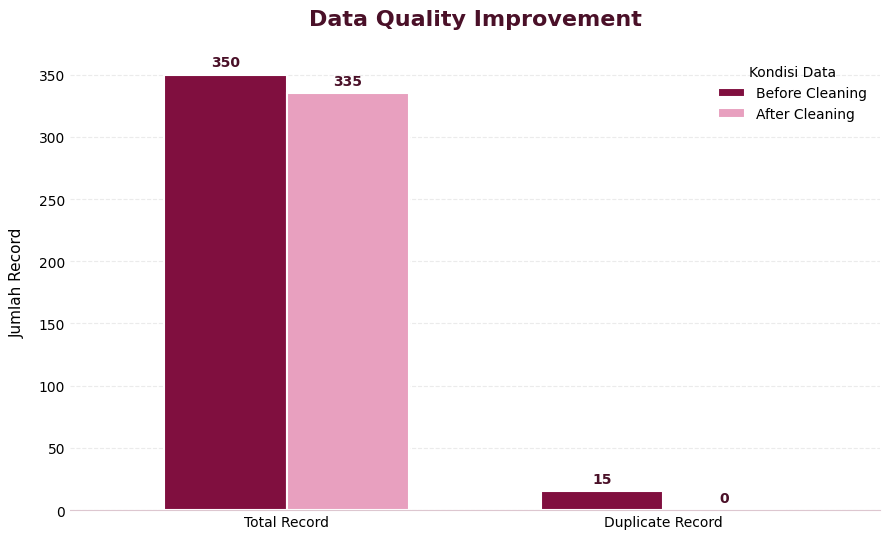

In [51]:

# Data perbandingan sebelum dan sesudah cleaning
comparison = pd.DataFrame({
    "Before": [
        len(df),
        df.duplicated().sum()
    ],
    "After": [
        len(df_clean),
        df_clean.duplicated().sum()
    ]
}, index=[
    "Total Record",
    "Duplicate Record"
])

# Palet warna maroon dan pink
maroon = "#800F3F"
pink = "#E8A0BF"

# Membuat grafik
ax = comparison.plot(
    kind="bar",
    figsize=(9, 5.5),
    color=[maroon, pink],
    width=0.65,
    edgecolor="white",
    linewidth=1.5
)

# Judul dan label
ax.set_title(
    "Data Quality Improvement",
    fontsize=16,
    fontweight="bold",
    pad=20,
    color="#4A1028"
)

ax.set_ylabel("Jumlah Record", fontsize=11, labelpad=10)
ax.set_xlabel("")

ax.set_xticklabels(
    comparison.index,
    rotation=0,
    fontsize=10
)

# Label angka di atas setiap batang
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=4,
        fontsize=10,
        fontweight="bold",
        color="#4A1028"
    )

# Tampilan lebih bersih
ax.set_axisbelow(True)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color("#DDC7D0")

ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", length=0)

# Legenda
ax.legend(
    title="Kondisi Data",
    labels=["Before Cleaning", "After Cleaning"],
    frameon=False,
    loc="upper right"
)

plt.tight_layout()
plt.show()


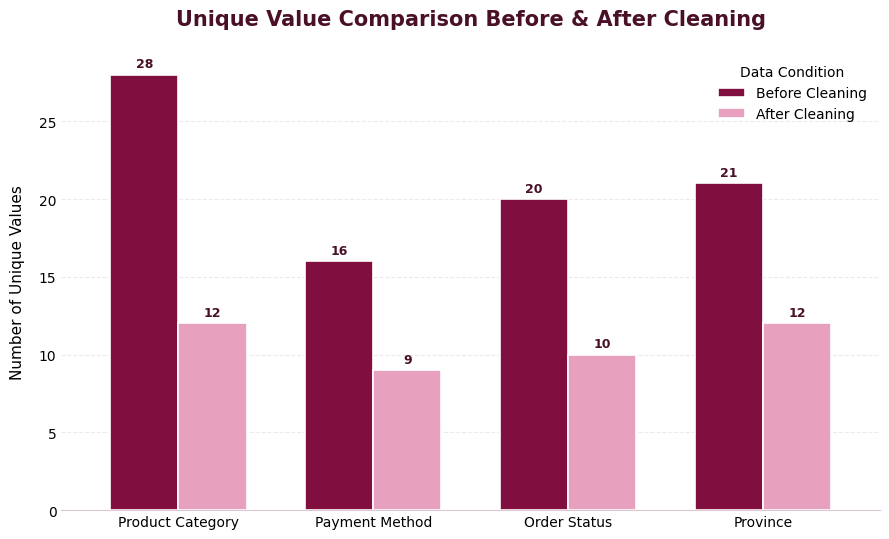

In [52]:

import matplotlib.pyplot as plt
import pandas as pd

# Perbandingan unique value sebelum dan sesudah cleaning
unique_chart = pd.DataFrame({
    "Before": [
        df["product_category"].nunique(),
        df["payment_method"].nunique(),
        df["order_status"].nunique(),
        df["province"].nunique()
    ],
    "After": [
        df_clean["product_category"].nunique(),
        df_clean["payment_method"].nunique(),
        df_clean["order_status"].nunique(),
        df_clean["province"].nunique()
    ]
}, index=[
    "Product Category",
    "Payment Method",
    "Order Status",
    "Province"
])

# Palet warna maroon dan pink
maroon = "#800F3F"
pink = "#E8A0BF"
dark_maroon = "#4A1028"

# Membuat grafik
ax = unique_chart.plot(
    kind="bar",
    figsize=(9, 5.5),
    color=[maroon, pink],
    width=0.7,
    edgecolor="white",
    linewidth=1.2
)

# Judul dan label
ax.set_title(
    "Unique Value Comparison Before & After Cleaning",
    fontsize=15,
    fontweight="bold",
    color=dark_maroon,
    pad=20
)

ax.set_ylabel("Number of Unique Values", fontsize=11, labelpad=10)
ax.set_xlabel("")

ax.set_xticklabels(
    unique_chart.index,
    rotation=0,
    ha="center",
    fontsize=10
)

# Label angka pada setiap batang
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=3,
        fontsize=9,
        fontweight="bold",
        color=dark_maroon
    )

# Grid dan tampilan minimalis
ax.set_axisbelow(True)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color("#DDC7D0")
ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", length=0)

# Legenda
ax.legend(
    title="Data Condition",
    labels=["Before Cleaning", "After Cleaning"],
    frameon=False
)

plt.tight_layout()
plt.show()

## **4. Export Quality Report**

In [50]:
quality_summary.to_csv(
    "final_quality_report.csv",
    index=False
)


print(
    "Quality report berhasil dibuat"
)

Quality report berhasil dibuat
